<a href="https://colab.research.google.com/github/CarrintonAyuk/-ICE-Task-2-classification-algorithms-/blob/main/RNN_vs_GRU_ice_Task_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RNN vs GRU for Sentiment Analysis on IMDb Movie Reviews

## ICE TASK 3 PDAN8412

## Student name: Carrinton Ayuk

## Student num: ST10541422

## October 2026

## 1. Import Libraries

In [93]:
import pandas as pd
import numpy as np
import re
import time

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

### We Set a seed so the results can be repeated

In [9]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

tf.keras.utils.set_random_seed(42)

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the Dataset
The IMDb dataset contains 50,000 movie reviews labelled as positive or negative.
It is downloaded directly from Kaggle.

we are loadingh dataset directly from kaggle since its the best recommended route

In [10]:
import kagglehub
import os

path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
print("Dataset folder:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Dataset folder: /kaggle/input/imdb-dataset-of-50k-movie-reviews
['IMDB Dataset.csv']


In [11]:
df = pd.read_csv(os.path.join(path, "IMDB Dataset.csv"))
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 3. Explore the Data
Now we check the size of the dataset, the data types, missing values, duplicates and the balance of the classes.

In [12]:
print(df.shape)
df.info()

(50000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [13]:
print(df.isnull().sum())

duplicate_count = df.duplicated().sum()
print(f"Duplicate reviews: {duplicate_count}")

review       0
sentiment    0
dtype: int64
Duplicate reviews: 418


There are no missing values but we have duplicates so we dont need thode duplicates, we then remove  them

In [14]:
df = df.drop_duplicates(subset = ["review"], keep = "first")
print(df.shape)

(49582, 2)


### 3.1 Class Distribution
Count the positive and negative reviews to check whether the classes are balanced.

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


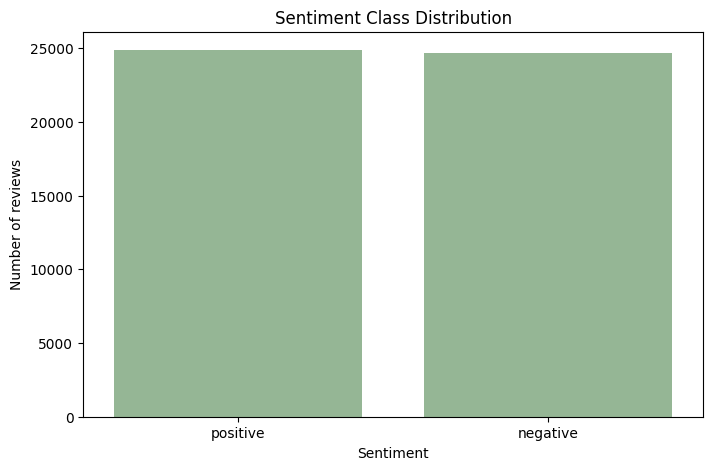

In [21]:
class_count = df["sentiment"].value_counts()
print(class_count)

plt.figure(figsize = (8, 5))
sns.countplot(data = df, x = "sentiment", color = "#8FBC8F")
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.show()

The classes are almost equal, so the dataset is balanced and accuracy is a fair measure of model performance.

### 3.2 Review Length
Count the number of words in each review to see how long the reviews are.
This helps choose the padding length later.

count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: word_count, dtype: float64


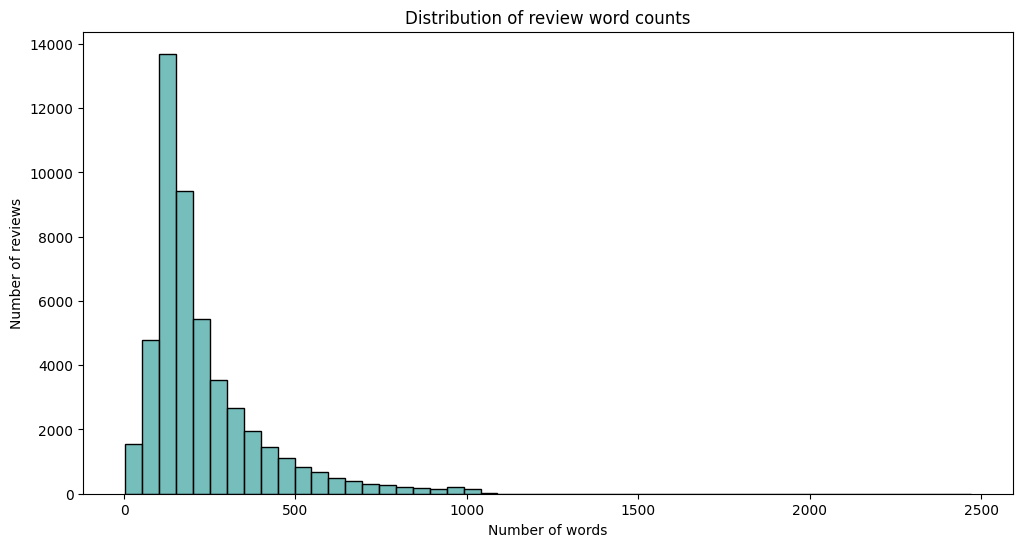

In [20]:
df["word_count"] = df["review"].astype(str).apply(lambda x: len(x.split()))
print(df["word_count"].describe())

plt.figure(figsize = (12, 6))
sns.histplot(data = df, x = "word_count", bins = 50, color = "#48A9A6")
plt.title("Distribution of review word counts")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.show()

The chart is skewed to the right. which says most reviews are short to medium length, with an average of about 230 words,
while a small number of reviews are much longer (over 2,000 words).
Padding every review to the longest length would waste memory, so a shorter maximum length will be chosen later.

## 4. Clean the Text
The reviews contain HTML tags such as <br />, links, capital letters and punctuation that do not help the model.
A cleaning function converts the text to lowercase, removes HTML tags and links, keeps only letters and apostrophes,
and removes extra spaces.

In [17]:
def clean_review(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)            #remove HTML tags such as <br />
    text = re.sub(r"http\S+|www\S+", " ", text)   #remove links
    text = re.sub(r"[^a-z']", " ", text)          #keep only letters and apostrophes
    text = re.sub(r"\s+", " ", text)              #remove extra spaces
    text = text.strip()

    return text

In [18]:
df["clean_review"] = df["review"].apply(clean_review)

### 4.1 Compare the Original and Cleaned Reviews
A sample of reviews is shown before and after cleaning to check that the function worked properly

In [19]:
comparison = df[["review", "clean_review"]].sample(5, random_state = 42)
comparison

,review,clean_review
29171,"""Soul Plane"" is a horrible attempt at comedy t...",soul plane is a horrible attempt at comedy tha...
43589,Guest from the Future tells a fascinating stor...,guest from the future tells a fascinating stor...
38712,"""National Treasure"" (2004) is a thoroughly mis...",national treasure is a thoroughly misguided ho...
16045,"OK. First said, I just wanted to check whether...",ok first said i just wanted to check whether t...
5248,"I haven't always been a fan, but the show grew...",i haven't always been a fan but the show grew ...


 cleaned reviews are in lowercase and no longer contain HTML tags, links or punctuation,
so only the words that carry meaning are passed to the model.

## 5. Encode the Labels
The model cannot read the words "positive" and "negative", so LabelEncoder converts them to numbers.

- Convert the classes into numerical values

- View the mapping

In [22]:

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["sentiment"])

In [23]:

for number, sentiment in enumerate(label_encoder.classes_):
    print(f"{number}: {sentiment}")

0: negative
1: positive


Negative reviews are labelled 0 and positive reviews are labelled 1.

### 5.1 Split the Data
The data is split into three sets. 30% is kept as the test set, used only once for the final comparison.
The remaining data is split again, with 20% used as a validation set to compare the hyperparameters.
Stratify keeps the same balance of positive and negative reviews in every set.

now we selecting our X and Y axis

In [25]:

x = df["clean_review"]
y = df["label"]

In [26]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.3, random_state = 42, stratify = y)

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size = 0.2, random_state = 42, stratify = y_train)

In [27]:
print(f"Training set: {len(x_train)}")
print(f"Validation set: {len(x_val)}")
print(f"Test set: {len(x_test)}")

Training set: 27765
Validation set: 6942
Test set: 14875


The training set is used to train the models, the validation set is used to choose the best hyperparameters,
and the test set is kept aside until the final evaluation so the comparison is fair.

## 6. Tokenize the Reviews
The Tokenizer gives every word a number based on how often it appears in the training reviews.
Only the 10,000 most common words are kept. Words outside this list are replaced with "<OOV>" (out of vocabulary).
The tokenizer is fitted on the training set only, so no information from the validation or test sets is used.

In [28]:
max_words = 10000
tokenizer = Tokenizer(num_words = max_words, oov_token = "<OOV>")
tokenizer.fit_on_texts(x_train)

In [29]:
word_index = tokenizer.word_index
print(f"Vocab_size: {len(word_index)}")

Vocab_size: 92286


- Convert the text to sequences of numbers

In [30]:

x_train_seq = tokenizer.texts_to_sequences(x_train)
x_val_seq = tokenizer.texts_to_sequences(x_val)
x_test_seq = tokenizer.texts_to_sequences(x_test)

print("Review as words:", x_train.iloc[0][:100])
print("Review as numbers:", x_train_seq[0][:15])

Review as words: easily one of my favourite dramatic tv films in many ways beautiful yet sad heart warming and though
Review as numbers: [725, 28, 5, 57, 1692, 951, 235, 104, 8, 106, 799, 315, 240, 634, 489]


Each review is now a list of numbers. The vocabulary contains many more words than the 10,000 kept,
but the rarer words appear too seldom to help the model learn.

### 6.1 Choose the Sequence Length
The lengths of the tokenized reviews are checked to choose a sensible maximum length for padding.

In [31]:
sequence_lengths = [len(sequence) for sequence in x_train_seq]
print(pd.Series(sequence_lengths).describe())
print("75% of reviews are shorter than:", np.percentile(sequence_lengths, 75))

count    27765.000000
mean       230.506861
std        171.157493
min          6.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2462.000000
dtype: float64
75% of reviews are shorter than: 280.0


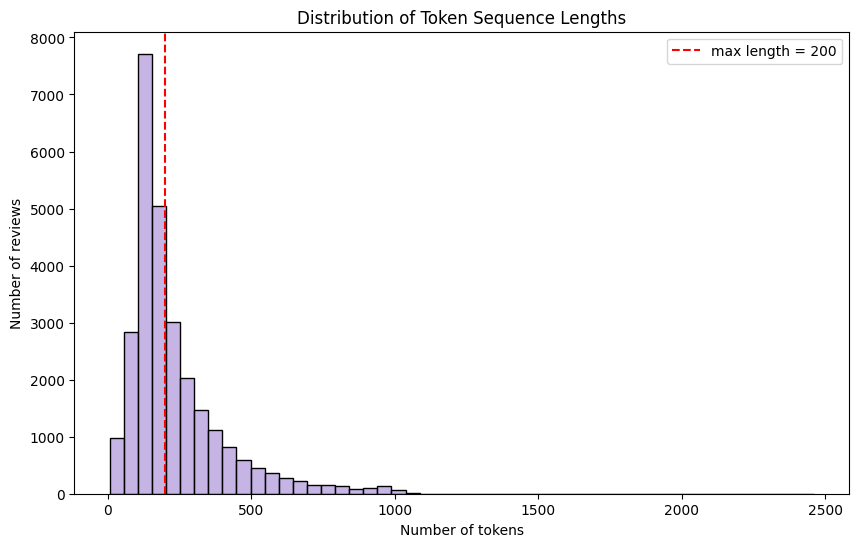

In [33]:
plt.figure(figsize = (10, 6))
sns.histplot(sequence_lengths, bins = 50, color = "#B39DDB")
plt.axvline(200, color = "red", linestyle = "--", label = "max length = 200")
plt.title("Distribution of Token Sequence Lengths")
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.legend()
plt.show()

we have maximum length of 200 tokens covers most of the review content while keeping training time manageable.
Longer reviews are cut and shorter reviews are padded with zeros.

### 6.2 Pad the Sequences
Padding gives every review the same length so they can be passed to the model together.
Zeros are added at the start of short reviews ("pre" padding), so the real words are the last thing
the recurrent layer reads before making its prediction. Long reviews keep their last 200 words,
which usually contain the reviewer's final opinion.

In [34]:
max_sequences = 200
x_train = pad_sequences(x_train_seq, maxlen = max_sequences, padding = "pre", truncating = "pre")
x_val = pad_sequences(x_val_seq, maxlen = max_sequences, padding = "pre", truncating = "pre")
x_test = pad_sequences(x_test_seq, maxlen = max_sequences, padding = "pre", truncating = "pre")

- Check the shape of the three sets

training , validation , testing

In [35]:

print(f"training_shape: {x_train.shape}")
print(f"validation_shape: {x_val.shape}")
print(f"testing_shape: {x_test.shape}")

training_shape: (27765, 200)
validation_shape: (6942, 200)
testing_shape: (14875, 200)


## 7. Build the Models
Both models follow the same structure:
- an Embedding layer that turns each word number into a dense vector of 64 values
- one or more recurrent layers (SimpleRNN or GRU) that read the review word by word
- a Dropout layer that switches off 30% of the neurons during training to reduce overfitting
- a Dense output layer with a sigmoid activation, which returns a probability between 0 (negative) and 1 (positive)

A function is used so the number of hidden layers can be changed during hyperparameter tuning.
The only difference between the two models is the type of recurrent layer.

- first we choose the type of recurrent layer
- next embedding layer: converts each word number into a dense vector
- Recurrent layers: every layer except the last passes its full sequence to the next layer
- Now Dropout layer: randomly disables 30% of the neurons to reduce overfitting
- Output layer: one probability, 0 = negative and 1 = positive
- For binary classification, we use the binary_crossentropy loss function

In [36]:
def build_model(model_type, n_layers, units = 64):

    if model_type == "RNN":
        Layer = SimpleRNN
    else:
        Layer = GRU

    model = Sequential()

    model.add(Embedding(input_dim = max_words, output_dim = 64))

    ### Recurrent layers: every layer except the last passes its full sequence to the next layer
    for i in range(n_layers):
        last_layer = (i == n_layers - 1)
        model.add(Layer(units, return_sequences = not last_layer))

    ### Dropout layer: randomly disables 30% of the neurons to reduce overfitting
    model.add(Dropout(0.3))

    ### Output layer: one probability, 0 = negative and 1 = positive
    model.add(Dense(1, activation = "sigmoid"))

    ### For binary classification, we use the binary_crossentropy loss function
    model.compile(optimizer = "adam", loss = "binary_crossentropy", metrics = ["accuracy"])

    model.build(input_shape = (None, max_sequences))
    return model

### 7.1 RNN Model

In [37]:
rnn_model = build_model("RNN", n_layers = 2)
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 200, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 656,577 (2.50 MB)

 Trainable params: 656,577 (2.50 MB)

 Non-trainable params: 0 (0.00 B)

### 7.2 GRU Model

In [38]:
gru_model = build_model("GRU", n_layers = 2)
gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 200, 64)        │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 689,985 (2.63 MB)

 Trainable params: 689,985 (2.63 MB)

 Non-trainable params: 0 (0.00 B)

Both models have the same layers, but each GRU layer has about three times as many parameters as a SimpleRNN layer.
The extra parameters belong to the GRU's gates (the update gate and reset gate), which decide what information to keep
and what to forget. This should help the GRU remember the start of long reviews, but it also means more calculations per step.

## 8. Hyperparameter Tuning
A grid search is used to test every combination of:
- number of hidden layers: 1, 2, 3 and 4
- batch size: 32, 64 and 128
- number of epochs: 1 to 5

Each combination of layers and batch size is trained once for 5 epochs, and the results are recorded
at the end of every epoch. This gives the same results as training separate models for 1, 2, 3, 4 and 5 epochs.
For every experiment, the accuracy, loss, validation accuracy, validation loss and training time are recorded.

- one row for every model, layers, batch size and epoch
- training history of every run, used later for the plots

In [39]:
layer_options = [1, 2, 3, 4]
batch_options = [32, 64, 128]
max_epochs = 5

results = []
histories = {}

### 8.1 Training Time Recorder
A callback records how long training has taken at the end of each epoch.

In [40]:
class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs = None):
        self.start = time.time()
        self.times = []

    def on_epoch_end(self, epoch, logs = None):
        self.times.append(time.time() - self.start)

### 8.2 Experiment Function
The function builds a model, trains it, and saves the metrics for every epoch.
The results are saved to a CSV file after every run, so nothing is lost if Colab disconnects.

In [41]:
def run_experiment(model_type, n_layers, batch_size):
    tf.keras.utils.set_random_seed(42)
    model = build_model(model_type, n_layers)
    timer = EpochTimer()

    history = model.fit(
        x_train, y_train,
        validation_data = (x_val, y_val),
        epochs = max_epochs,
        batch_size = batch_size,
        callbacks = [timer],
        verbose = 0
    )

    histories[(model_type, n_layers, batch_size)] = history.history

    ### it record the metrics at every epoch
    for e in range(max_epochs):
        results.append({
            "model": model_type,
            "layers": n_layers,
            "batch_size": batch_size,
            "epochs": e + 1,
            "accuracy": history.history["accuracy"][e],
            "loss": history.history["loss"][e],
            "val_accuracy": history.history["val_accuracy"][e],
            "val_loss": history.history["val_loss"][e],
            "train_time_sec": timer.times[e]
        })

    pd.DataFrame(results).to_csv("tuning_results.csv", index = False)

    print(f"{model_type} | layers = {n_layers} | batch = {batch_size} | "
          f"best val_accuracy = {max(history.history['val_accuracy']):.4f} | "
          f"time = {timer.times[-1]:.0f}s")

### 8.3 Tuning the RNN Model

In [45]:
for n_layers in layer_options:
    for batch_size in batch_options:
        run_experiment("RNN", n_layers, batch_size)

RNN | layers = 1 | batch = 32 | best val_accuracy = 0.6605 | time = 79s
RNN | layers = 1 | batch = 64 | best val_accuracy = 0.8280 | time = 45s
RNN | layers = 1 | batch = 128 | best val_accuracy = 0.8423 | time = 25s
RNN | layers = 2 | batch = 32 | best val_accuracy = 0.7684 | time = 149s
RNN | layers = 2 | batch = 64 | best val_accuracy = 0.8284 | time = 74s
RNN | layers = 2 | batch = 128 | best val_accuracy = 0.8300 | time = 42s
RNN | layers = 3 | batch = 32 | best val_accuracy = 0.8166 | time = 203s
RNN | layers = 3 | batch = 64 | best val_accuracy = 0.7855 | time = 108s
RNN | layers = 3 | batch = 128 | best val_accuracy = 0.8182 | time = 60s
RNN | layers = 4 | batch = 32 | best val_accuracy = 0.5001 | time = 317s
RNN | layers = 4 | batch = 64 | best val_accuracy = 0.7289 | time = 161s
RNN | layers = 4 | batch = 128 | best val_accuracy = 0.7483 | time = 77s


### 8.4 Tuning the GRU Model

In [46]:
for n_layers in layer_options:
    for batch_size in batch_options:
        run_experiment("GRU", n_layers, batch_size)

GRU | layers = 1 | batch = 32 | best val_accuracy = 0.8819 | time = 54s
GRU | layers = 1 | batch = 64 | best val_accuracy = 0.8745 | time = 28s
GRU | layers = 1 | batch = 128 | best val_accuracy = 0.8676 | time = 16s
GRU | layers = 2 | batch = 32 | best val_accuracy = 0.8751 | time = 83s
GRU | layers = 2 | batch = 64 | best val_accuracy = 0.8660 | time = 43s
GRU | layers = 2 | batch = 128 | best val_accuracy = 0.8680 | time = 24s
GRU | layers = 3 | batch = 32 | best val_accuracy = 0.8793 | time = 111s
GRU | layers = 3 | batch = 64 | best val_accuracy = 0.8731 | time = 59s
GRU | layers = 3 | batch = 128 | best val_accuracy = 0.8712 | time = 33s
GRU | layers = 4 | batch = 32 | best val_accuracy = 0.8804 | time = 156s
GRU | layers = 4 | batch = 64 | best val_accuracy = 0.8732 | time = 73s
GRU | layers = 4 | batch = 128 | best val_accuracy = 0.8698 | time = 42s


In total, 24 models were trained (12 RNN and 12 GRU), giving 120 recorded results across the different epochs.
The GRU runs trained noticeably faster than the RNN runs, because Colab's GPU has an optimised implementation for GRU layers
that SimpleRNN cannot use.

In [57]:
print(results_df.shape)

(285, 9)


In [58]:
#Remove the repeated GRU runs and keep the most recent one
results_df = results_df.drop_duplicates(subset = ["model", "layers", "batch_size", "epochs"], keep = "last")
print(results_df.shape)

(120, 9)


## 9. Tuning Results
The recorded results are loaded into a table and compared to see how the number of hidden layers,
batch size and number of epochs affected each model.

In [59]:
results_df = pd.read_csv("tuning_results.csv")
print(results_df.shape)
results_df.head(10)

(285, 9)


,model,layers,batch_size,epochs,accuracy,loss,val_accuracy,val_loss,train_time_sec
0,RNN,1,32,1,0.651720,0.611210,0.653414,0.609317,23.397837
1,RNN,1,32,2,0.763011,0.496933,0.711322,0.569429,38.754607
2,RNN,1,32,3,0.803710,0.444758,0.790118,0.464499,59.863699
3,RNN,1,32,4,0.828201,0.405808,0.808845,0.470627,80.138691
4,RNN,1,32,5,0.732469,0.523246,0.574474,1.170565,94.587624
5,RNN,1,64,1,0.709562,0.554866,0.833477,0.397211,13.974070
6,RNN,1,64,2,0.769134,0.484548,0.670268,0.687777,21.463279
7,RNN,1,64,3,0.823555,0.422843,0.814319,0.442181,29.005705
8,RNN,1,64,4,0.818585,0.411523,0.757563,0.506684,36.371731
9,RNN,1,64,5,0.863065,0.331354,0.801930,0.488595,43.917896


### 9.1 Best Configuration for Each Model
The best configuration is the one with the highest validation accuracy.

In [60]:
best_rows = results_df.loc[results_df.groupby("model")["val_accuracy"].idxmax()]
best_rows.round(4)

,model,layers,batch_size,epochs,accuracy,loss,val_accuracy,val_loss,train_time_sec
91,GRU,3,32,2,0.8995,0.2572,0.8846,0.2891,45.7659
28,RNN,2,128,4,0.8595,0.3379,0.8470,0.3461,38.5342


we check Top 5 configurations for each model

In [61]:

for model_type in ["RNN", "GRU"]:
    print(f"\nTop 5 {model_type} configurations:")
    top5 = results_df[results_df["model"] == model_type].sort_values("val_accuracy", ascending = False).head(5)
    print(top5.round(4).to_string(index = False))


Top 5 RNN configurations:
model  layers  batch_size  epochs  accuracy   loss  val_accuracy  val_loss  train_time_sec
  RNN       2         128       4    0.8595 0.3379        0.8470    0.3461         38.5342
  RNN       1         128       3    0.8973 0.2672        0.8423    0.3951         17.2528
  RNN       1         128       2    0.8483 0.3591        0.8404    0.3753         13.3795
  RNN       1         128       4    0.9220 0.2051        0.8379    0.4396         21.1283
  RNN       3         128       4    0.8879 0.2910        0.8374    0.3858         49.0951

Top 5 GRU configurations:
model  layers  batch_size  epochs  accuracy   loss  val_accuracy  val_loss  train_time_sec
  GRU       3          32       2    0.8995 0.2572        0.8846    0.2891         45.7659
  GRU       1          32       2    0.9002 0.2546        0.8845    0.2797         28.4665
  GRU       1          32       2    0.8945 0.2663        0.8819    0.2883         22.5689
  GRU       3          32       3   

The best GRU configuration was 3 hidden layers, a batch size of 32 and 2 epochs, with a validation accuracy of 88.46%.
The best RNN configuration was 2 hidden layers, a batch size of 128 and 4 epochs, with a validation accuracy of 84.70%.

The top 5 tables show that the GRU results were very close to each other (all above 88%), and that batch size 32 with
2 epochs was consistently the best setting. A 1-layer GRU reached almost the same accuracy (88.45%) in less time
(28 seconds compared to 46 seconds), which confirms that extra GRU layers added little.
All of the top 5 RNN configurations used a batch size of 128, and the RNN needed more epochs (3 to 4) to reach its best result.

### 9.2 Effect of the Number of Hidden Layers
For each number of layers, the best validation accuracy across all batch sizes and epochs is shown.

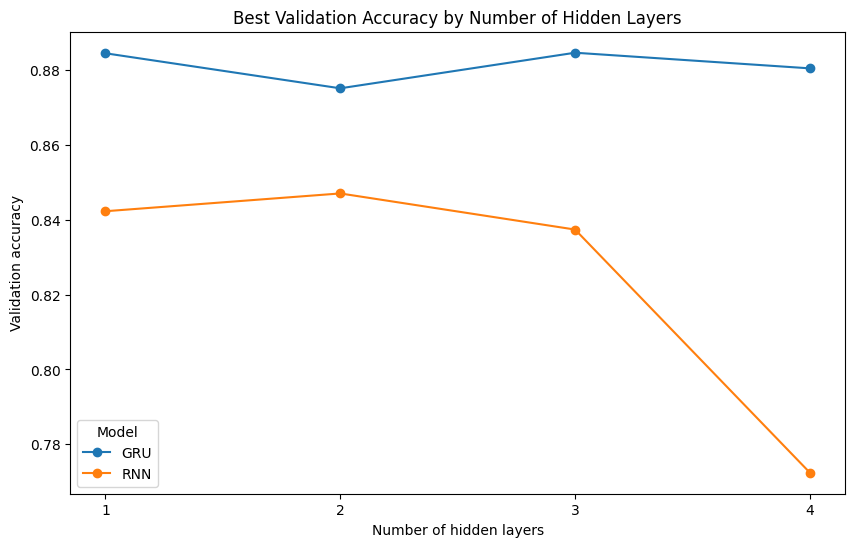

In [62]:
layer_effect = results_df.groupby(["model", "layers"])["val_accuracy"].max().unstack(0)

layer_effect.plot(marker = "o", figsize = (10, 6))
plt.title("Best Validation Accuracy by Number of Hidden Layers")
plt.xlabel("Number of hidden layers")
plt.ylabel("Validation accuracy")
plt.xticks(layer_options)
plt.legend(title = "Model")
plt.show()

The GRU stayed stable across all depths, with a best validation accuracy of about 88% whether it had 1, 2, 3 or 4 layers.
Adding layers did not improve it, which shows a single GRU layer is already enough to capture the sentiment of a review.

The RNN performed best with 2 layers (about 85%), but its accuracy fell sharply to about 77% with 4 layers.
SimpleRNN layers suffer from the vanishing gradient problem: as more layers are stacked, the learning signal
becomes weaker as it travels back through the network, so the deeper RNN struggled to train.
The GRU's gates protect it from this problem, which is why its accuracy did not drop.

### 9.3 Effect of Batch Size

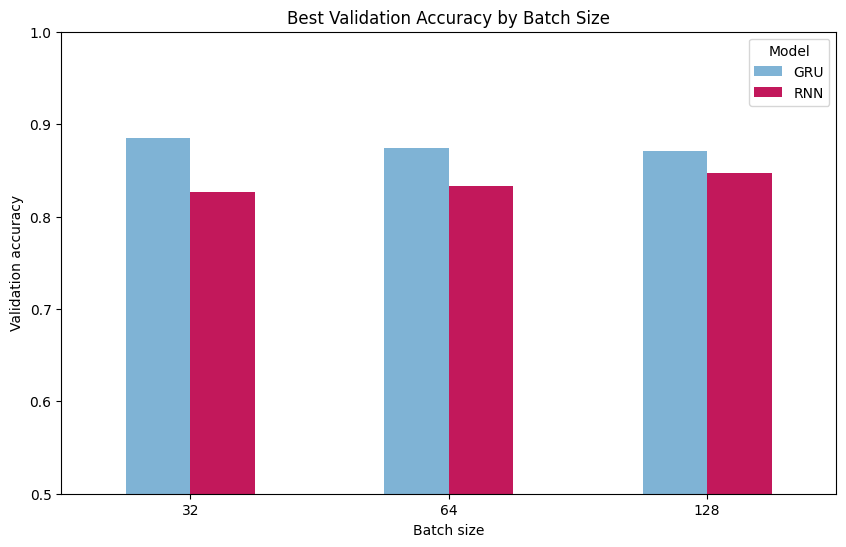

In [63]:
batch_effect = results_df.groupby(["model", "batch_size"])["val_accuracy"].max().unstack(0)

batch_effect.plot(kind = "bar", figsize = (10, 6), color = ["#7FB3D5", "#C2185B"])
plt.title("Best Validation Accuracy by Batch Size")
plt.xlabel("Batch size")
plt.ylabel("Validation accuracy")
plt.ylim(0.5, 1.0)
plt.xticks(rotation = 0)
plt.legend(title = "Model")
plt.show()

### 9.4 Effect of the Number of Epochs
The average training and validation accuracy at each epoch shows how the models learn over time.

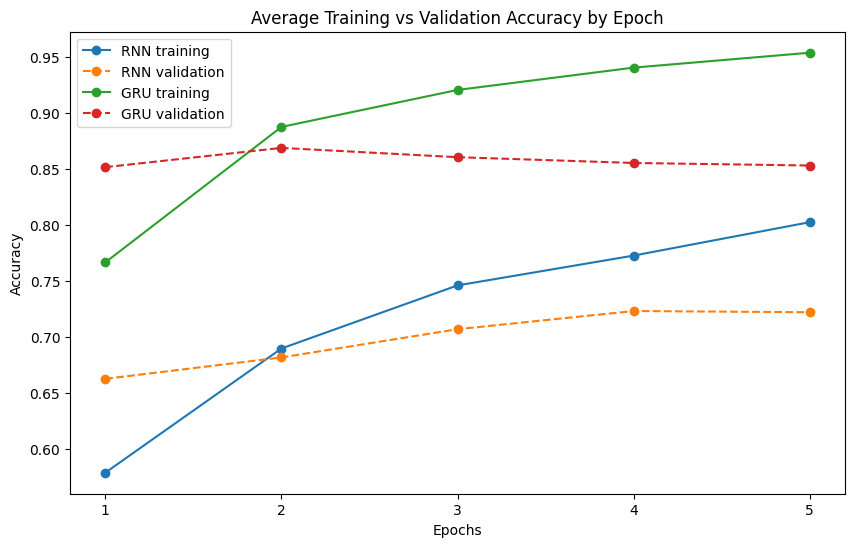

In [64]:
epoch_effect = results_df.groupby(["model", "epochs"])[["accuracy", "val_accuracy"]].mean().reset_index()

plt.figure(figsize = (10, 6))
for model_type in ["RNN", "GRU"]:
    data = epoch_effect[epoch_effect["model"] == model_type]
    plt.plot(data["epochs"], data["accuracy"], marker = "o", label = f"{model_type} training")
    plt.plot(data["epochs"], data["val_accuracy"], marker = "o", linestyle = "--", label = f"{model_type} validation")
plt.title("Average Training vs Validation Accuracy by Epoch")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(range(1, max_epochs + 1))
plt.legend()
plt.show()

The chart shows the average accuracy across all configurations at each epoch.
The GRU learned quickly: its validation accuracy peaked at about 87% at epoch 2 and then slowly fell,
while its training accuracy kept rising to about 95%. The growing gap after epoch 2 shows the GRU began to overfit.

The RNN learned more slowly. Its training accuracy rose from about 58% to 80%, while its validation accuracy only rose
from about 66% to 72%, levelling off after epoch 4. On average, the RNN was still underfitting after 5 epochs,
which is why its best results needed more epochs than the GRU.

Batch size had only a small effect. The GRU performed slightly better with smaller batches,
reaching its best accuracy (about 88.5%) with a batch size of 32, as smaller batches update the weights more often.
The RNN showed the opposite pattern, improving from about 83% at batch size 32 to about 85% at batch size 128.
Larger batches give a smoother, more stable gradient, which helps the less stable SimpleRNN train.

### 9.5 Overfitting and Underfitting
The training and validation loss of the best configuration for each model is plotted.
If the training loss keeps falling while the validation loss rises, the model is overfitting.
If both losses stay high, the model is underfitting.

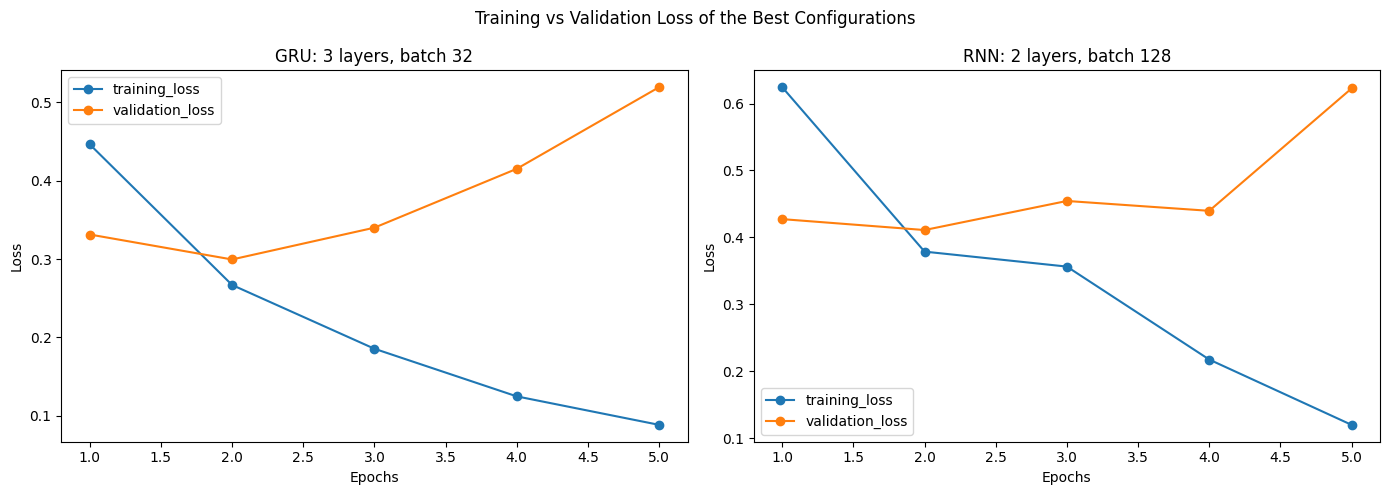

In [65]:
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

for ax, (_, row) in zip(axes, best_rows.iterrows()):
    key = (row["model"], int(row["layers"]), int(row["batch_size"]))
    h = histories[key]
    ax.plot(range(1, max_epochs + 1), h["loss"], marker = "o", label = "training_loss")
    ax.plot(range(1, max_epochs + 1), h["val_loss"], marker = "o", label = "validation_loss")
    ax.set_title(f"{key[0]}: {key[1]} layers, batch {key[2]}")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Loss")
    ax.legend()

plt.suptitle("Training vs Validation Loss of the Best Configurations")
plt.tight_layout()
plt.show()

Both best models show clear overfitting after the second epoch.
For the GRU (3 layers, batch 32), the training loss kept falling from 0.45 to 0.09, while the validation loss
reached its lowest point of 0.30 at epoch 2 and then rose to 0.52 by epoch 5.
The RNN (2 layers, batch 128) followed the same pattern: its validation loss was lowest at epoch 2 (0.41)
and rose to 0.62 by epoch 5, while its training loss kept falling.
This means both models started memorising the training reviews instead of learning general patterns.
Training for about 2 epochs, or using early stopping, gives the best results.

Underfitting was seen in the 4-layer RNN, which could not reach the accuracy of the shallower RNNs
because the vanishing gradient problem made it hard to train.

### 9.6 Training Time

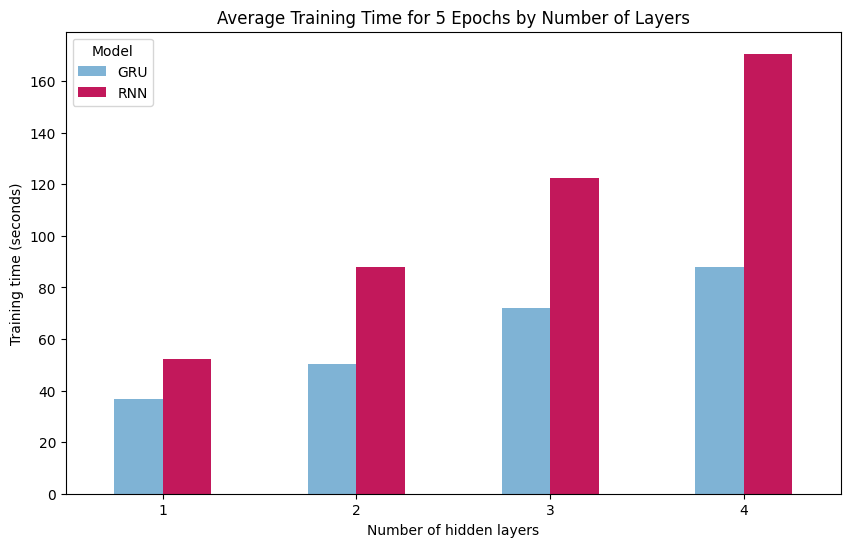

In [66]:
time_effect = results_df[results_df["epochs"] == max_epochs].groupby(["model", "layers"])["train_time_sec"].mean().unstack(0)

time_effect.plot(kind = "bar", figsize = (10, 6), color = ["#7FB3D5", "#C2185B"])
plt.title("Average Training Time for 5 Epochs by Number of Layers")
plt.xlabel("Number of hidden layers")
plt.ylabel("Training time (seconds)")
plt.xticks(rotation = 0)
plt.legend(title = "Model")
plt.show()

Training time increased with every extra layer for both models, but the GRU was consistently faster.
With 4 layers, the RNN took about 170 seconds for 5 epochs compared to about 88 seconds for the GRU.
Although a GRU layer has more parameters, Colab's GPU uses an optimised (cuDNN) implementation for GRU layers,
while SimpleRNN layers are processed one step at a time.

## 10. Final Training and Test Evaluation
The best configuration for each model, chosen using the validation results, is trained one last time.
Both models are then evaluated on the test set, which has not been used at any earlier stage.

- Best settings from the tuning results

In [81]:

best_settings = {}
for _, row in best_rows.iterrows():
    best_settings[row["model"]] = {
        "layers": int(row["layers"]),
        "batch_size": int(row["batch_size"]),
        "epochs": int(row["epochs"])
    }

print(best_settings)

{'GRU': {'layers': 3, 'batch_size': 32, 'epochs': 2}, 'RNN': {'layers': 2, 'batch_size': 128, 'epochs': 4}}


### 10.1 Train the Final Models

In [82]:
final_models = {}
final_times = {}

for model_type in ["RNN", "GRU"]:
    settings = best_settings[model_type]
    tf.keras.utils.set_random_seed(42)
    model = build_model(model_type, settings["layers"])

    start = time.time()
    model.fit(
        x_train, y_train,
        validation_data = (x_val, y_val),
        epochs = settings["epochs"],
        batch_size = settings["batch_size"],
        verbose = 1
    )
    final_times[model_type] = time.time() - start
    final_models[model_type] = model

    print(f"{model_type} training time: {final_times[model_type]:.1f} seconds\n")

Epoch 1/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - accuracy: 0.6064 - loss: 0.6425 - val_accuracy: 0.7194 - val_loss: 0.5595
Epoch 2/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.8372 - loss: 0.3845 - val_accuracy: 0.8377 - val_loss: 0.3808
Epoch 3/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.8997 - loss: 0.2580 - val_accuracy: 0.8008 - val_loss: 0.5211
Epoch 4/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.9338 - loss: 0.1772 - val_accuracy: 0.7420 - val_loss: 0.6512
RNN training time: 36.6 seconds

Epoch 1/2
868/868 ━━━━━━━━━━━━━━━━━━━━ 25s 26ms/step - accuracy: 0.7890 - loss: 0.4420 - val_accuracy: 0.8712 - val_loss: 0.3192
Epoch 2/2
868/868 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.8984 - loss: 0.2590 - val_accuracy: 0.8814 - val_loss: 0.2925
GRU training time: 46.6 seconds



###  Train the Final Models with Earlystopping
The best number of layers and batch size from tuning are used for each model.
Early stopping is added: each model can train for up to 10 epochs, but training stops when the validation loss
has not improved for 2 epochs in a row, and the weights from the best epoch are restored.
This prevents the overfitting seen during tuning and protects against an unlucky final epoch.

- Stop when the validation loss stops improving and keep the best weights

In [83]:
final_models = {}
final_times = {}
final_histories = {}

for model_type in ["RNN", "GRU"]:
    settings = best_settings[model_type]
    tf.keras.utils.set_random_seed(42)
    model = build_model(model_type, settings["layers"])

    early_stopping = EarlyStopping(monitor = "val_loss", patience = 2, restore_best_weights = True)

    start = time.time()
    history = model.fit(
        x_train, y_train,
        validation_data = (x_val, y_val),
        epochs = 10,
        batch_size = settings["batch_size"],
        callbacks = [early_stopping],
        verbose = 1
    )
    final_times[model_type] = time.time() - start
    final_models[model_type] = model
    final_histories[model_type] = history.history

    best_epoch = np.argmin(history.history["val_loss"]) + 1
    print(f"{model_type}: trained for {len(history.history['loss'])} epochs, best epoch = {best_epoch}")
    print(f"{model_type} training time: {final_times[model_type]:.1f} seconds\n")

Epoch 1/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - accuracy: 0.5854 - loss: 0.6568 - val_accuracy: 0.7177 - val_loss: 0.5527
Epoch 2/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.8212 - loss: 0.4109 - val_accuracy: 0.8248 - val_loss: 0.4008
Epoch 3/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.8399 - loss: 0.3748 - val_accuracy: 0.8270 - val_loss: 0.4305
Epoch 4/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.9078 - loss: 0.2376 - val_accuracy: 0.8369 - val_loss: 0.4591
RNN: trained for 4 epochs, best epoch = 2
RNN training time: 36.8 seconds

Epoch 1/10
868/868 ━━━━━━━━━━━━━━━━━━━━ 25s 25ms/step - accuracy: 0.7888 - loss: 0.4411 - val_accuracy: 0.8722 - val_loss: 0.3126
Epoch 2/10
868/868 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.8999 - loss: 0.2587 - val_accuracy: 0.8738 - val_loss: 0.2991
Epoch 3/10
868/868 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.9331 - loss: 0.1844 - val_accuracy: 0.8793 - val_loss: 0.3414
Epoch 4/10
868/868

Early stopping chose the best epoch for each model automatically, based on the lowest validation loss.
Both models trained for 4 epochs and kept the weights from epoch 2.
At its best epoch, the RNN had a validation accuracy of 82.48% and the GRU 87.38%.
Both stopped 2 epochs after their best result, as set by the patience value.

### 10.2 Training vs Validation Loss of the Final Models
Each review is predicted as positive when the model's probability is above 0.5.
Accuracy, precision, recall and F1-score are calculated on the test set.

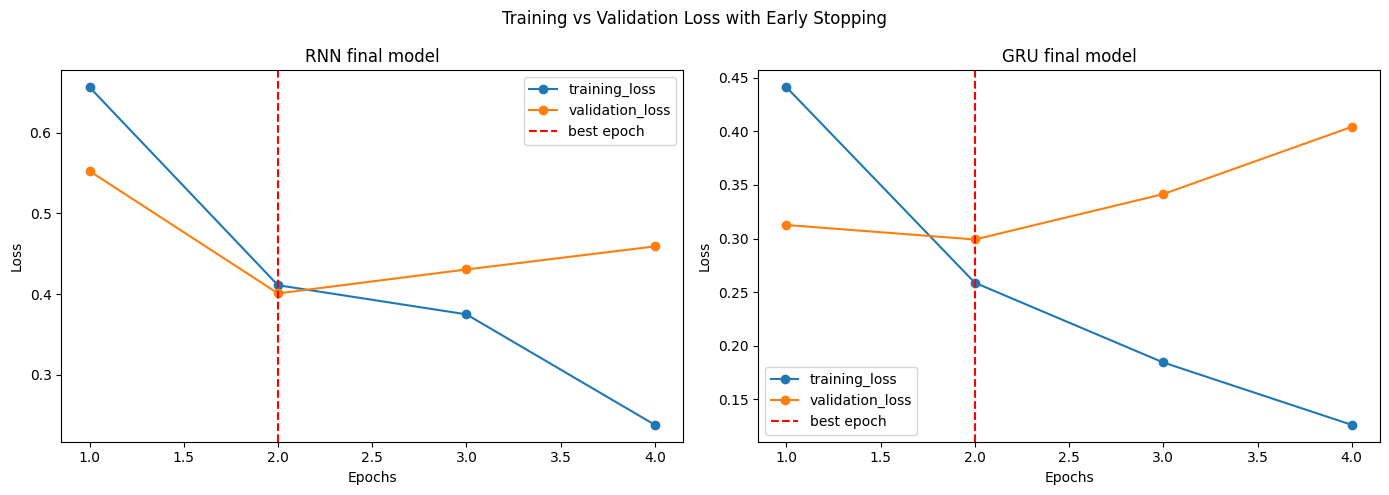

In [84]:
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

for ax, model_type in zip(axes, ["RNN", "GRU"]):
    h = final_histories[model_type]
    epochs_range = range(1, len(h["loss"]) + 1)
    ax.plot(epochs_range, h["loss"], marker = "o", label = "training_loss")
    ax.plot(epochs_range, h["val_loss"], marker = "o", label = "validation_loss")
    ax.axvline(np.argmin(h["val_loss"]) + 1, color = "red", linestyle = "--", label = "best epoch")
    ax.set_title(f"{model_type} final model")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Loss")
    ax.legend()

plt.suptitle("Training vs Validation Loss with Early Stopping")
plt.tight_layout()
plt.show()

Both models show the same pattern seen during tuning: the training loss keeps falling, while the validation loss
is lowest at epoch 2 and then rises, which is a sign of overfitting. Early stopping detected this and restored
the weights from epoch 2 (marked with the red line).

For the RNN, validation accuracy kept rising slightly after epoch 2 (to 83.69% at epoch 4) even though the validation
loss rose. This means the model was becoming over-confident in its wrong predictions. Validation loss was used to choose
the best epoch because it measures how confident the predictions are, not only whether they are right.

- test results and classification reports

In [90]:
final_results = []
predictions = {}

for model_type in ["RNN", "GRU"]:
    model = final_models[model_type]

    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose = 0)

    start = time.time()
    y_probability = model.predict(x_test, verbose = 0)
    prediction_time = time.time() - start

    y_pred = (y_probability > 0.5).astype(int).ravel()
    predictions[model_type] = y_pred

    final_results.append({
        "model": model_type,
        "layers": best_settings[model_type]["layers"],
        "batch_size": best_settings[model_type]["batch_size"],
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "training_time_sec": final_times[model_type],
        "prediction_time_sec": prediction_time
    })

    print(f"\n{model_type} Classification Report")
    print(classification_report(y_test, y_pred, target_names = label_encoder.classes_))

final_df = pd.DataFrame(final_results)
final_df.round(4)


RNN Classification Report
              precision    recall  f1-score   support

    negative       0.82      0.84      0.83      7410
    positive       0.84      0.82      0.83      7465

    accuracy                           0.83     14875
   macro avg       0.83      0.83      0.83     14875
weighted avg       0.83      0.83      0.83     14875


GRU Classification Report
              precision    recall  f1-score   support

    negative       0.87      0.88      0.88      7410
    positive       0.88      0.87      0.88      7465

    accuracy                           0.88     14875
   macro avg       0.88      0.88      0.88     14875
weighted avg       0.88      0.88      0.88     14875



,model,layers,batch_size,test_loss,test_accuracy,precision,recall,f1_score,training_time_sec,prediction_time_sec
0,RNN,2,128,0.3899,0.8311,0.8393,0.8205,0.8298,36.8273,4.7479
1,GRU,3,32,0.2932,0.8763,0.8829,0.8687,0.8758,90.8088,4.7427


On the test set of 14,875 unseen reviews, the GRU achieved 87.63% accuracy compared to 83.11% for the RNN,
an improvement of about 4.5 percentage points. The GRU was also better on every other metric:
precision of 0.883 against 0.839, recall of 0.869 against 0.821, and an F1-score of 0.876 against 0.830.
The GRU's test loss (0.29) was also lower than the RNN's (0.39), meaning its predictions were more confident and more often correct.

Both models treated the two classes fairly evenly. The RNN recognised negative reviews slightly better (recall 0.84)
than positive ones (0.82), and the GRU was balanced on both (0.88 and 0.87).

Early stopping clearly helped the RNN: without it, the same RNN configuration reached only 78.00% test accuracy,
because it ended training on an overfitted epoch.

### 10.3 Confusion Matrices
The confusion matrix shows how many reviews of each class were predicted correctly and incorrectly.
The dark boxes on the diagonal are correct predictions, and the light boxes are errors.

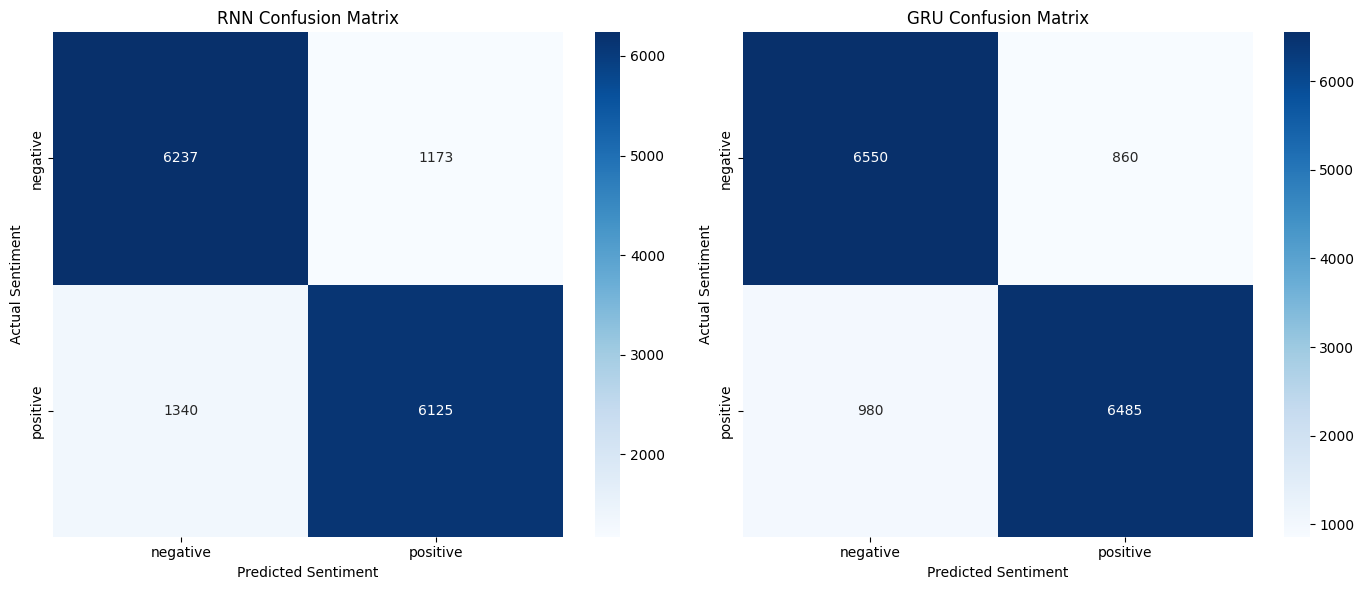

In [92]:
fig, axes = plt.subplots(1, 2, figsize = (14, 6))

for ax, model_type in zip(axes, ["RNN", "GRU"]):
    cm = confusion_matrix(y_test, predictions[model_type])
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", ax = ax,
                xticklabels = label_encoder.classes_, yticklabels = label_encoder.classes_)
    ax.set_title(f"{model_type} Confusion Matrix")
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

The RNN misclassified 2,513 reviews: 1,173 negative reviews were predicted as positive,
and 1,340 positive reviews were predicted as negative.
The GRU misclassified only 1,840 reviews: 860 negative reviews were predicted as positive,
and 980 positive reviews were predicted as negative.
The GRU therefore made about 27% fewer errors than the RNN.

### 10.4 Final Comparison: RNN vs GRU

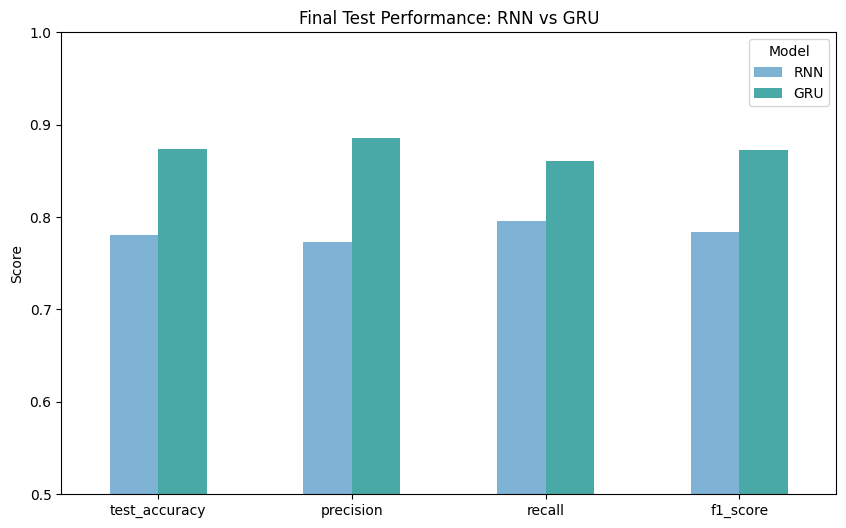

In [87]:
metrics = ["test_accuracy", "precision", "recall", "f1_score"]
comparison = final_df.set_index("model")[metrics].T

comparison.plot(kind = "bar", figsize = (10, 6), color = ["#7FB3D5", "#48A9A6"])
plt.title("Final Test Performance: RNN vs GRU")
plt.ylabel("Score")
plt.ylim(0.5, 1.0)
plt.xticks(rotation = 0)
plt.legend(title = "Model")
plt.show()

The GRU outperformed the RNN on all four metrics, by between 4 and 5 percentage points each,
with the largest gap in recall.

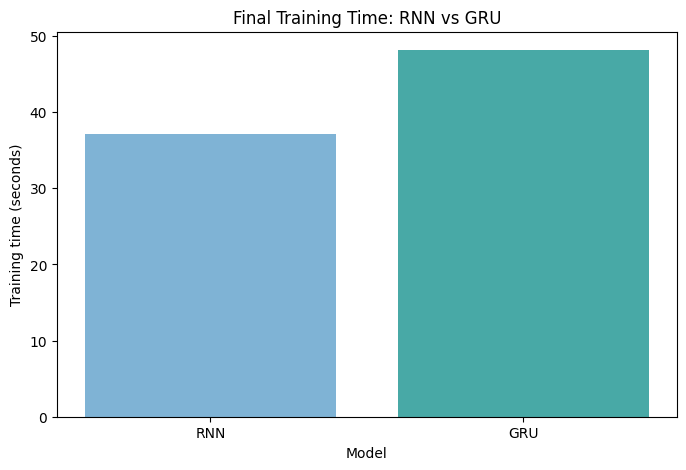

In [88]:
plt.figure(figsize = (8, 5))
plt.bar(final_df["model"], final_df["training_time_sec"], color = ["#7FB3D5", "#48A9A6"])
plt.title("Final Training Time: RNN vs GRU")
plt.xlabel("Model")
plt.ylabel("Training time (seconds)")
plt.show()

The final GRU took longer to train (91 seconds) than the final RNN (37 seconds). This is because the GRU used a batch size of 32,
giving 868 training steps per epoch, while the RNN used a batch size of 128 with only 217 steps. Early stopping also ran
2 extra epochs for each model to confirm they had stopped improving. When both models used the same settings during tuning,
the GRU was consistently faster (see section 9.6), because Colab's GPU has an optimised implementation for GRU layers.

## 11. Conclusion

**Effect of the hyperparameters.** Adding hidden layers did not improve either model. The GRU stayed at about 88%
validation accuracy with 1 to 4 layers, while the RNN dropped from 85% with 2 layers to 77% with 4 layers because of
the vanishing gradient problem. Batch size had a small effect: the GRU worked best with batch size 32 and the RNN with 128.
The number of epochs mattered most, as both models reached their best results after only 2 to 4 epochs and then began to overfit.

**Overfitting and underfitting.** Both models overfitted after about epoch 2, as training loss kept falling while
validation loss rose. Early stopping solved this by restoring the weights from the best epoch, which raised the RNN's
test accuracy from 78.00% to 83.11%. The deepest RNN (4 layers) underfitted, as it could not learn as well as the shallower RNNs.

**Final comparison.** The GRU was the better model. It achieved 87.63% test accuracy compared to 83.11% for the RNN,
and was better on precision, recall and F1-score, making about 27% fewer errors. It also gave more consistent results
when retrained, and with equal settings it trained faster. The GRU's gates allow it to remember important words from
earlier in a long review, which a simple RNN struggles to do. For sentiment analysis of long texts such as movie reviews,
the GRU is the recommended model.